# Задание для индивидуальной работы No3 (Вариант А)

### 1.Блок. Pandas

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("competition_1.csv", delimiter=";")
df.head()

,Фамилия,Имя,Пол,Год рождения,"Бег 1000 метров, мин. и сек.","Бег 30 метров, сек.","Прыжок в длину с места, см"
0,Абдуллаев,Денис,м,1998,"3,42","4,72",188
1,Абдуллаев,Темур,м,1999,"5,12","5,63",187
2,Абраменцев,Владислав,м,1997,"5,52","5,42",223
3,Абсалямов,Илья,м,1999,"5,43","4,92",237
4,Авдонин,Александр,м,1998,"4,38","4,71",219


In [3]:
def time_to_seconds(val):
    if pd.isna(val):
        return None
    val_str = str(val).replace(",", ".")
    parts = val_str.split(".")
    if len(parts) == 2:
        return int(parts[0]) * 60 + int(parts[1])
    return int(val_str) * 60


df["1000 м, сек"] = df["Бег 1000 метров, мин. и сек."].apply(time_to_seconds)

In [4]:
df["Бег 30 метров, сек."] = (
    df["Бег 30 метров, сек."].str.replace(",", ".").astype(float)
)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Фамилия                       1000 non-null   str    
 1   Имя                           1000 non-null   str    
 2   Пол                           1000 non-null   str    
 3   Год рождения                  1000 non-null   int64  
 4   Бег 1000 метров, мин. и сек.  1000 non-null   str    
 5   Бег 30 метров, сек.           1000 non-null   float64
 6   Прыжок в длину с места, см    1000 non-null   int64  
 7   1000 м, сек                   1000 non-null   int64  
dtypes: float64(1), int64(3), str(4)
memory usage: 62.6 KB


#### 1.1

In [5]:
df.groupby(["Год рождения", "Пол"])["1000 м, сек"].agg(
    Среднее="mean", Медиана="median"
).round(2)

Среднее  Медиана
Год рождения Пол                  
1996         ж     283.81    285.0
             м     284.06    286.0
1997         ж     280.82    278.0
             м     286.89    287.5
1998         ж     290.32    292.0
             м     287.74    283.0
1999         ж     287.82    292.0
             м     285.00    285.0

#### 1.2

In [6]:
sports = {
    "Бег 1000 метров, мин. и сек.": True,
    "Бег 30 метров, сек.": True,
    "Прыжок в длину с места, см ": False,
}


for sport, ascending in sports.items():
    print(f"\n{'=' * 60}")
    print(f"ВИД: {sport}")
    print(f"{'=' * 60}")

    df["Место"] = df.groupby(["Год рождения", "Пол"])[sport].rank(
        method="dense", ascending=ascending
    )

    winners = df[df["Место"] <= 3].copy()

    for year in sorted(winners["Год рождения"].unique()):
        for gender in ["ж", "м"]:
            subset = winners[
                (winners["Год рождения"] == year) & (winners["Пол"] == gender)
            ].sort_values("Место")

            if not subset.empty:
                print(
                    f"\n--- {year} год, {'девочки' if gender == 'д' else 'мальчики'} ---"
                )
                print(subset[["Место", "Фамилия", "Имя", sport]].to_string(index=False))


ВИД: Бег 1000 метров, мин. и сек.

--- 1996 год, мальчики ---
 Место      Фамилия       Имя Бег 1000 метров, мин. и сек.
   1.0      Коркина Анастасия                         3,28
   2.0      Иванова      Анна                          3,3
   3.0 Трапезникова     Мария                         3,33

--- 1996 год, мальчики ---
 Место  Фамилия    Имя Бег 1000 метров, мин. и сек.
   1.0   Бурсов Никита                         3,28
   2.0 Бессонов Кирилл                          3,3
   3.0  Бохонов  Антон                         3,33

--- 1997 год, мальчики ---
 Место   Фамилия       Имя Бег 1000 метров, мин. и сек.
   1.0  Бирюкова     Злата                         3,28
   1.0 Гайдамака Екатерина                         3,28
   1.0   Мошкина   Татьяна                         3,28
   2.0  Яруллина   Татьяна                          3,3
   3.0  Соколова     Марта                         3,32

--- 1997 год, мальчики ---
 Место Фамилия     Имя Бег 1000 метров, мин. и сек.
   1.0 Чеканов Евгени

#### 1.3

In [7]:
sports = {
    "1000 м, сек": True,  # Используем переведенное в секунды время
    "Бег 30 метров, сек.": True,
    "Прыжок в длину с места, см ": False,
}

girls = df[df["Пол"] == "ж"].copy()

for sport, ascending in sports.items():
    print(f"\n{'=' * 60}")
    print(f"ВИД СПОРТА: {sport}")
    print(f"{'=' * 60}")

    # Считаем ранг внутри каждого года для этого вида спорта
    girls[f"Ранг {sport}"] = girls.groupby(["Год рождения"])[sport].rank(
        method="min", ascending=ascending
    )

    # Отбираем ТОП-5
    top5 = girls[girls[f"Ранг {sport}"] <= 5].copy()

    # Выводим результаты по годам
    for year in sorted(top5["Год рождения"].unique()):
        group = top5[top5["Год рождения"] == year].sort_values(f"Ранг {sport}")

        print(f"\n--- {year} год ---")
        print(group[[f"Ранг {sport}", "Фамилия", "Имя", sport]].to_string(index=False))


ВИД СПОРТА: 1000 м, сек

--- 1996 год ---
 Ранг 1000 м, сек    Фамилия       Имя  1000 м, сек
              1.0    Иванова      Анна          183
              2.0  Андрякова     Ирина          184
              2.0 Артамонова   Татьяна          184
              2.0 Жданникова       Яна          184
              5.0    Коркина Анастасия          208

--- 1997 год ---
 Ранг 1000 м, сек    Фамилия       Имя  1000 м, сек
              1.0   Яруллина   Татьяна          183
              2.0 Костромина   Евгения          184
              2.0 Мухамедова   Камилла          184
              4.0   Богачева   Клавдия          185
              5.0  Гайдамака Екатерина          208
              5.0   Бирюкова     Злата          208
              5.0    Мошкина   Татьяна          208

--- 1998 год ---
 Ранг 1000 м, сек    Фамилия       Имя  1000 м, сек
              1.0   Лазурина Анастасия          184
              1.0   Себелева Екатерина          184
              3.0  Крутякова     Мари

### Блок. MatplotLib

In [8]:
import matplotlib.pyplot as plt

%matplotlib inline

Выведем количество участников с одинаковым возрастом

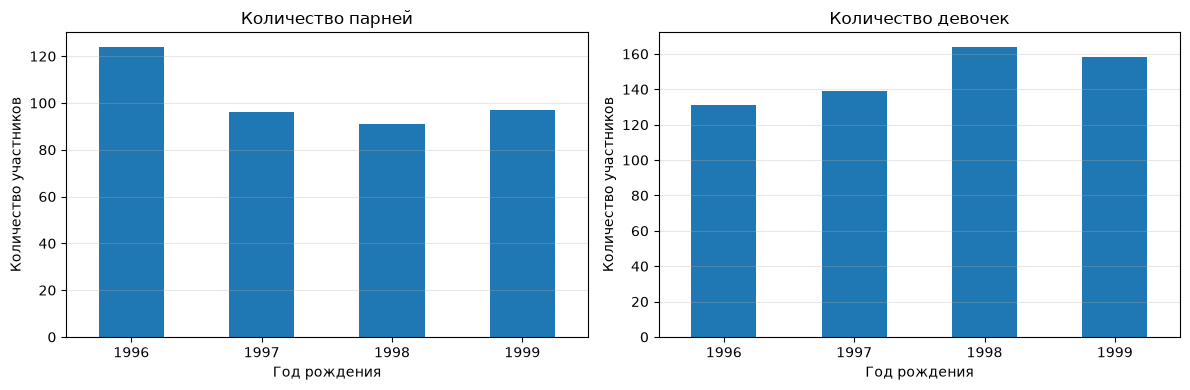

In [65]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
age_counts_m = df[df["Пол"] == "м"]["Год рождения"].value_counts().sort_index()
age_counts_m.plot(kind="bar")
plt.title("Количество парней")
plt.xlabel("Год рождения")
plt.ylabel("Количество участников")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.subplot(1, 2, 2)
age_counts_f = df[df["Пол"] == "ж"]["Год рождения"].value_counts().sort_index()
age_counts_f.plot(kind="bar")
plt.title("Количество девочек")
plt.xlabel("Год рождения")
plt.ylabel("Количество участников")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Построим boxplot для всех видов спорта

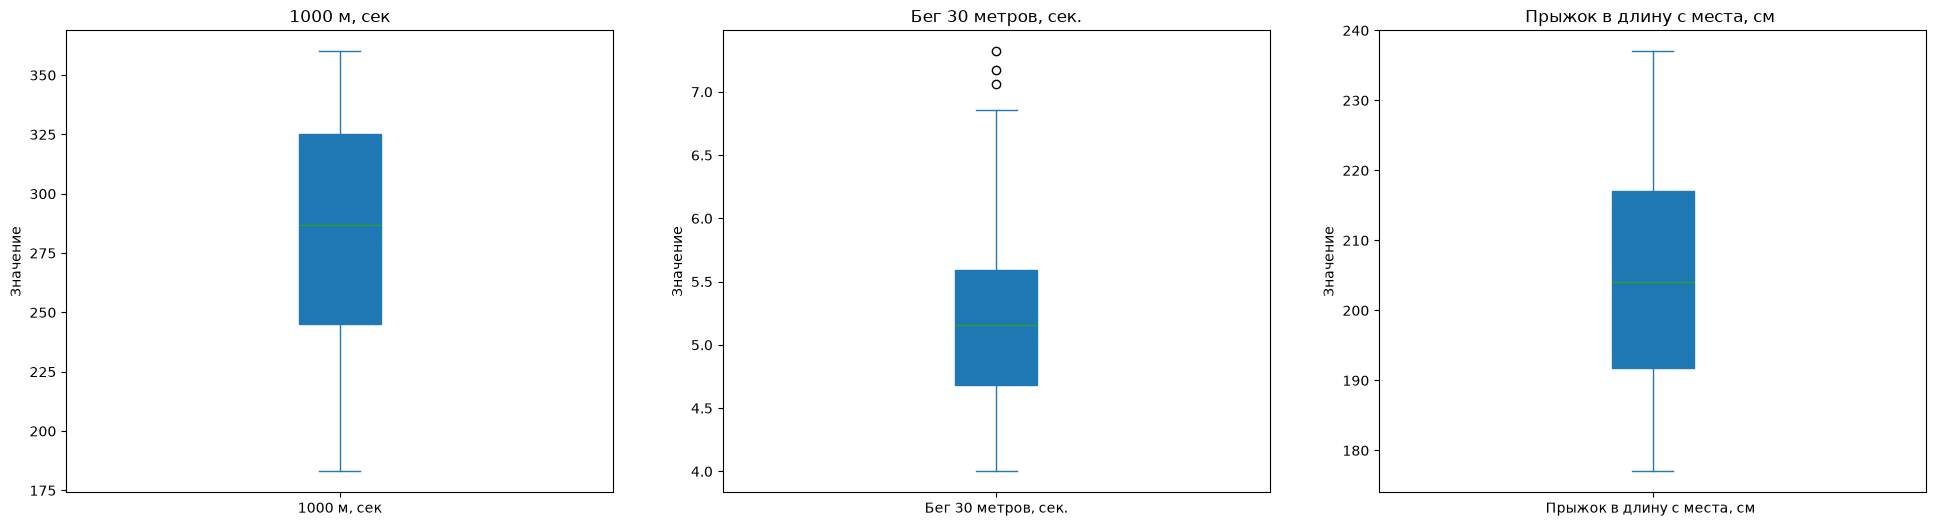

In [67]:
sports = [
    "1000 м, сек",
    "Бег 30 метров, сек.",
    "Прыжок в длину с места, см ",
]
fig, axes = plt.subplots(1, len(sports), figsize=(24, 6))

for sport, ax in zip(sports, axes):
    df.plot.box(y=sport, ax=ax, patch_artist=True)
    ax.set_title(sport, fontsize=12)
    ax.set_ylabel("Значение")

### Блок. Seaborn

In [68]:
import seaborn as sns  # подключаем библиотеку

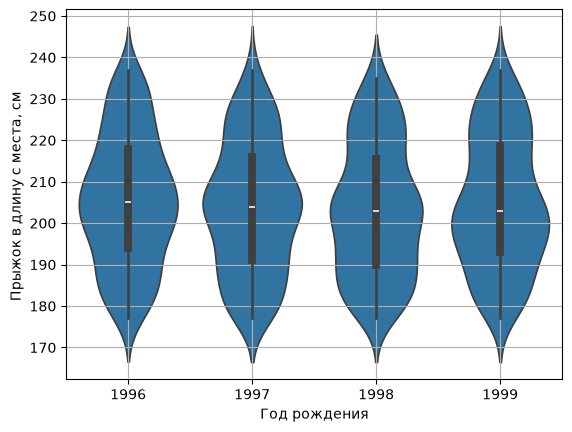

In [ ]:
sns.violinplot(x="Год рождения", y="Прыжок в длину с места, см ", data=df)
plt.grid(True)
plt.show()

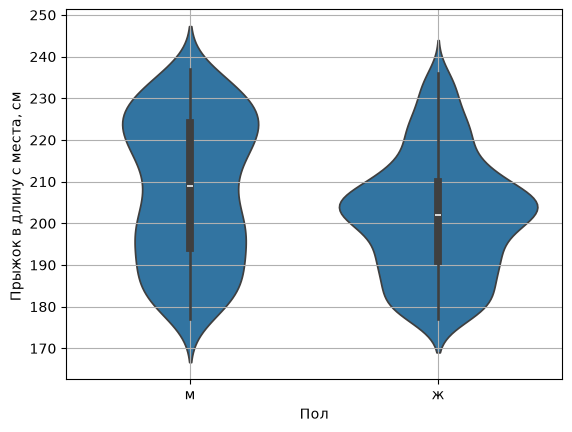

In [70]:
sns.violinplot(x="Пол", y="Прыжок в длину с места, см ", data=df)
plt.grid(True)
plt.show()

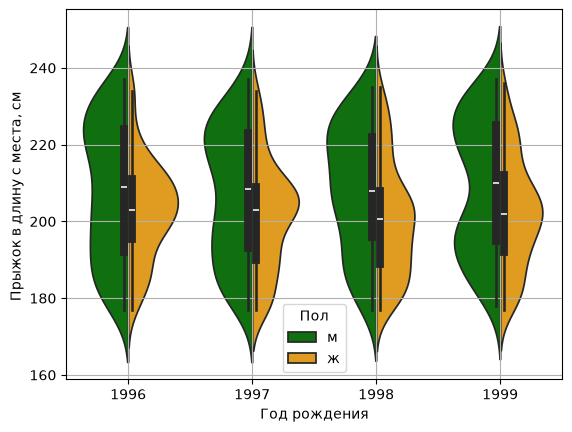

In [72]:
sns.violinplot(
    x="Год рождения",
    y="Прыжок в длину с места, см ",
    hue="Пол",
    split=True,
    palette=["green", "orange"],
    data=df,
)
plt.grid(True)
plt.show()